# Librerías

In [ ]:
import numpy as np #paquete para manejar arreglos
from matplotlib import pyplot as plt #para graficar

# https://numpy.org/doc/stable/reference/routines.polynomials.classes.html
from numpy.polynomial import Polynomial as Poly #para interpolar

# Detalle técnico no relevante
plt.rcParams["figure.figsize"] = (8,5) #tamaño de los gráficos: ancho x alto

---
# Mínimos cuadrados

- ## Charlar la idea de mínimos cuadrados: se propone función y se minimiza error cuadrático.

- ## Charlar la idea de regresión lineal

---

## Ejemplo 1 (regresión lineal): los siguientes datos corresponden a la población argentina expresada en millones de habitantes

\begin{align}
\begin{matrix}
\textbf{Año} & 1950 & 1960 & 1970 & 1980 & 1991 & 2001 & 2010\\ \hline
\textbf{Habitantes} & 17 & 20.5 & 23.9 & 27.9 & 32.6 & 36.3 & 40.1
\end{matrix}
\end{align}

1. ### Hallar la función $f(x)=a+bx$ que mejor aproxime a la tabla de datos en el sentido de cuadrados mínimos, resolviendo las ecuaciones normales.
2. ### Hacer un gráfico con los datos y la función encontrada.
1. ### Calcular error cuadrático medio y el coeficiente de indeterminación $R^2$. Interpretar.
1. ### Repetir 1. utilizando `numpy.polynomial` de cuando interpolamos en la P1. Comparar.


---
---

$ECM = \dfrac{1}{n} \sum_{j=0}^n (y^{*}_j - y_j)^2 = \dfrac{1}{n} \|Y^*-Y\|^2 $

$R^2 = \dfrac{\sum_{j=0}^n (y^{*}_j - \bar{y})^2}{\sum_{j=0}^n (y_j - \bar{y})^2}=\dfrac{\|Y^*-\bar{Y}\|^2}{\|Y-\bar{Y}\|^2}$

donde:
- La norma es la norma 2.
- $y^{*}$ es la estimación por cuadrados mínimos.
- $\bar{y}$ es el promedio de los datos.
- $y$ son los datos.

Coeficientes por ecuaciones normales: [-7.38644094e+02  3.87304044e-01]


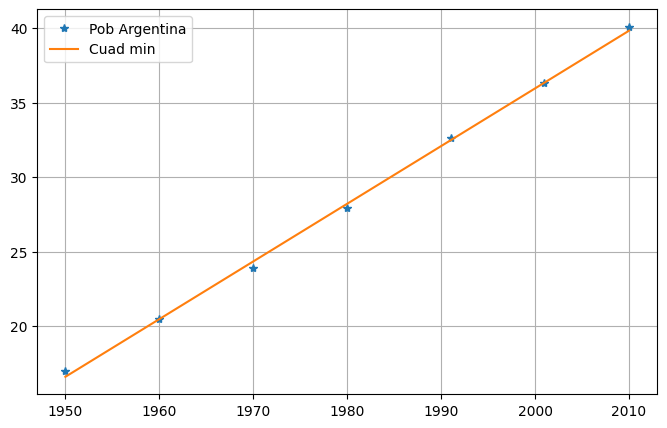

In [ ]:
# 1 y 2

# tabla de valores
tabla_x = np.array([1950, 1960, 1970, 1980, 1991, 2001, 2010])
tabla_y = np.array([17, 20.5, 23.9, 27.9, 32.6, 36.3, 40.1])


# ecuaciones normales
fila_de_unos = np.ones(len(tabla_x))
A_traspuesta = np.array([fila_de_unos, tabla_x])
A = np.transpose(A_traspuesta)

coefs = np.linalg.solve(np.dot(A_traspuesta,A), np.dot(A_traspuesta,tabla_y)) #en el orden en que lo definí en el sistema
print("Coeficientes por ecuaciones normales:", coefs)

# grafico tabla
plt.plot(tabla_x, tabla_y, '*', label='Pob Argentina')

#grafico cuad min
def cuad_min(x, a, b):
  y = a + b*x
  return y
a = coefs[0]
b = coefs[1]
vals_x_graficar = np.linspace(1950,2010,10**4)
plt.plot(vals_x_graficar, cuad_min(vals_x_graficar, a, b), label='Cuad min')
plt.legend()
plt.grid()

In [ ]:
# 3

# Error cuadrático medio
vals_y_cuad_min = cuad_min(tabla_x, a, b)
cant_datos = len(tabla_x)

ECM = (1/cant_datos)*np.linalg.norm(vals_y_cuad_min - tabla_y, ord=2)**2
print("Error cuadrático medio:", ECM)

tabla_y_promedio = np.mean(tabla_y)
R2 = np.linalg.norm(vals_y_cuad_min - tabla_y_promedio, ord=2)**2 / np.linalg.norm(tabla_y - tabla_y_promedio, ord=2)**2
# R2 = 1 - np.linalg.norm(vals_y_cuad_min - tabla_y, ord=2)**2 / np.linalg.norm(tabla_y - tabla_y_promedio, ord=2)**2
print("Coeficiente de determinación R2:", R2)

Error cuadrático medio: 0.07819221168248014
Coeficiente de determinación R2: 0.9987264350146003


Cuad min por numpy.polynomial: -738.64409386 + 0.38730404·x


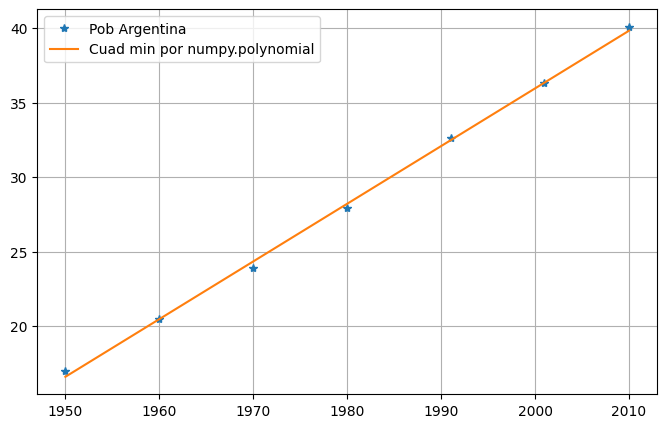

In [ ]:
# 4
tabla_x = np.array([1950, 1960, 1970, 1980, 1991, 2001, 2010])
tabla_y = np.array([17, 20.5, 23.9, 27.9, 32.6, 36.3, 40.1])

grado = 1
cuad_min_por_polynomial = Poly.fit(tabla_x, tabla_y, grado)
print("Cuad min por numpy.polynomial:", cuad_min_por_polynomial.convert()) # da igual que por ecuaciones normales


# grafico tabla y función de cuadrados mínimos
plt.plot(tabla_x, tabla_y, '*', label='Pob Argentina')

vals_x_graficar = np.linspace(1950,2010,10**4)
plt.plot(vals_x_graficar, cuad_min_por_polynomial(vals_x_graficar), label='Cuad min por numpy.polynomial')
plt.legend()
plt.grid()

---
## **Comentar que `numpy.polynomial` sirve para aproximar por mínimos cuadrados con funciones polinómicas de cualquier grado (no solamente grado 1 como acabamos de usar).**
---

## Ejemplo 2 (regresión no lineal, transformación): los siguientes datos corresponden a la población argentina expresada en millones de habitantes

\begin{align}
\begin{matrix}
\textbf{Año} & 1950 & 1960 & 1970 & 1980 & 1991 & 2001 & 2010\\ \hline
\textbf{Habitantes} & 17 & 20.5 & 23.9 & 27.9 & 32.6 & 36.3 & 40.1
\end{matrix}
\end{align}

1. ### Hallar la función $f(x)=a+b x^2$ que mejor aproxime a la tabla de datos en el sentido de cuadrados mínimos, resolviendo las ecuaciones normales.
  - ### ¿Podemos resolver por ecuaciones normales si la $f$ no es lineal?
  - ### ¿Y entonces qué hacemos? Escribir en papel esto.
2. ### Hacer un gráfico con los datos y la función encontrada.
1. ### Calcular error cuadrático medio. Interpretar y comparar con anteriores.

Error cuadrático medio: 0.06377003611243831


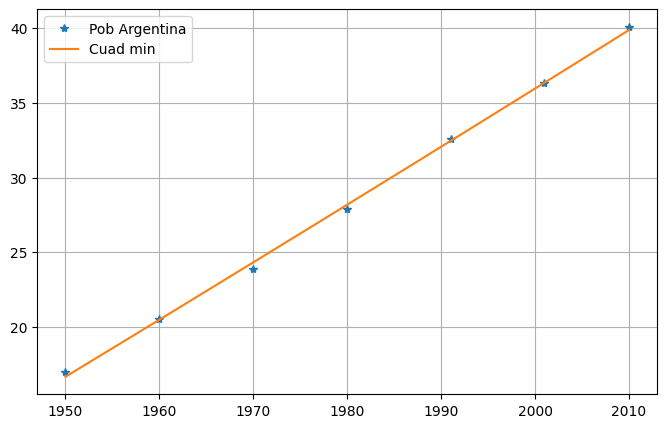

In [ ]:
# tabla valores original
tabla_x = np.array([1950, 1960, 1970, 1980, 1991, 2001, 2010])
tabla_y = np.array([17, 20.5, 23.9, 27.9, 32.6, 36.3, 40.1])

# tabla valores transformada para resolver por regresión lineal (ecuaciones normales)
tabla_t = tabla_x**2
# tabla_y queda igual

# ecuaciones normales
fila_de_unos = np.ones(len(tabla_t))
At = np.array([fila_de_unos, tabla_t])
A = np.transpose(At)

coefs = np.linalg.solve(np.dot(At,A), np.dot(At,tabla_y)) #en el orden en que lo definí en el sistema
# print("Coeficientes por ecuaciones normales:", coefs)

### también puedo calcular cuad min con numpy.polynomial
# por supuesto uso la tabla de datos transformados
# grado = 1
# cuad_min_por_polynomial = Poly.fit(tabla_t, tabla_y, grado)
###

# grafico tabla
plt.plot(tabla_x, tabla_y, '*', label='Pob Argentina')

# grafico cuad min
def cuad_min(x,a,b):
  y = a + b*x**2
  return y
a = coefs[0]
b = coefs[1]
vals_x_graficar = np.linspace(1950,2010,10**4)
# vals_x_graficar = np.linspace(0,2010, 5000) # ojo que parece lineal. Probar con esto.
plt.plot(vals_x_graficar, cuad_min(vals_x_graficar,a,b), label='Cuad min')
plt.legend()
plt.grid()

# Error cuadrático medio
vals_y_cuad_min = cuad_min(tabla_x,a,b)
cant_datos = len(tabla_x)

ECM = (1/cant_datos)*np.linalg.norm(vals_y_cuad_min - tabla_y, ord=2)**2
print("Error cuadrático medio:", ECM)

# tabla_y_promedio = np.mean(tabla_y)
# R2 = np.linalg.norm(vals_y_cuad_min - tabla_y_promedio, ord=2)**2 / np.linalg.norm(tabla_y - tabla_y_promedio, ord=2)**2
# R2 = 1 - np.linalg.norm(vals_y_cuad_min - tabla_y, ord=2)**2 / np.linalg.norm(tabla_y - tabla_y_promedio, ord=2)**2
# print("Coeficiente de determinación R2:", R2)

## Ejemplo 3 (regresión no lineal, transformación): los siguientes datos corresponden a la población argentina expresada en millones de habitantes

\begin{align}
\begin{matrix}
\textbf{Año} & 1950 & 1960 & 1970 & 1980 & 1991 & 2001 & 2010\\ \hline
\textbf{Habitantes} & 17 & 20.5 & 23.9 & 27.9 & 32.6 & 36.3 & 40.1
\end{matrix}
\end{align}

1. ### Hallar la función $f(x)=a\text{e}^{bx}$ que mejor aproxime a la tabla de datos en el sentido de cuadrados mínimos, resolviendo las ecuaciones normales.
  - ### ¿Podemos resolver por ecuaciones normales si la $f$ no es lineal?
  - ### ¿Y entonces qué hacemos? Escribir en papel esto.
2. ### Hacer un gráfico con los datos y la función encontrada.
1. ### Calcular error cuadrático medio. Interpretar y comparar con anteriores.

Error cuadrático medio: 0.6034479527032204


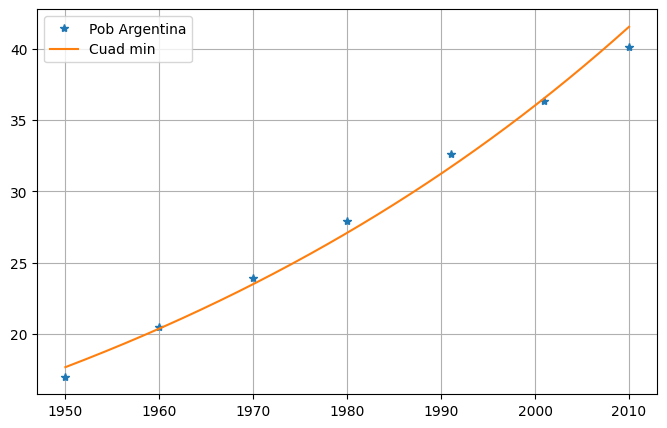

In [ ]:
# tabla valores original
tabla_x = np.array([1950, 1960, 1970, 1980, 1991, 2001, 2010])
tabla_y = np.array([17, 20.5, 23.9, 27.9, 32.6, 36.3, 40.1])

# tabla valores transformada para resolver por regresión lineal (ecuaciones normales)
# la tabla_x queda igual
tabla_z = np.log(tabla_y)

# ecuaciones normales
fila_de_unos = np.ones(len(tabla_x))
At = np.array([fila_de_unos, tabla_x])
A = np.transpose(At)

coefs = np.linalg.solve(np.dot(At,A), np.dot(At,tabla_z)) #en el orden en que lo definí en el sistema
# print("Coeficientes por ecuaciones normales:", coefs)

### también puedo calcular cuad min con numpy.polynomial
# por supuesto uso la tabla de datos transformados
# grado = 1
# cuad_min_por_polynomial = Poly.fit(tabla_x, tabla_z, grado)
###

# grafico tabla
plt.plot(tabla_x, tabla_y, '*', label='Pob Argentina')

# grafico cuad min
def cuad_min(x,a,b):
  y = a*np.exp(b*x)
  return y
a_monio = coefs[0]
b = coefs[1]
a = np.exp(a_monio)
vals_x_graficar = np.linspace(1950,2010, 5000)
plt.plot(vals_x_graficar, cuad_min(vals_x_graficar,a,b), label='Cuad min')
plt.legend()
plt.grid()

# Error cuadrático medio
vals_y_cuad_min = cuad_min(tabla_x,a,b)
cant_datos = len(tabla_x)

ECM = (1/cant_datos)*np.linalg.norm(vals_y_cuad_min - tabla_y, ord=2)**2
print("Error cuadrático medio:", ECM)

# tabla_y_promedio = np.mean(vals_y)
# R2 = 1 - np.linalg.norm(vals_y_cuad_min - tabla_y, ord=2)**2 / np.linalg.norm(tabla_y - tabla_y_promedio, ord=2)**2
# print("Coeficiente de determinación R2:", R2)

## Ejemplo 4 (regresión no lineal, transformación): los siguientes datos corresponden a la población argentina expresada en millones de habitantes

\begin{align}
\begin{matrix}
\textbf{Año} & 1950 & 1960 & 1970 & 1980 & 1991 & 2001 & 2010\\ \hline
\textbf{Habitantes} & 17 & 20.5 & 23.9 & 27.9 & 32.6 & 36.3 & 40.1
\end{matrix}
\end{align}

1. ### Hallar la función $f(x)=ax^b$ que mejor aproxime a la tabla de datos en el sentido de cuadrados mínimos, resolviendo las ecuaciones normales.
  - ### ¿Podemos resolver por ecuaciones normales si la $f$ no es lineal?
  - ### ¿Y entonces qué hacemos? Escribir en papel esto.
2. ### Hacer un gráfico con los datos y la función encontrada.
1. ### Calcular error cuadrático medio. Interpretar y comparar con anteriores.

Error cuadrático medio: 0.5502676972305706


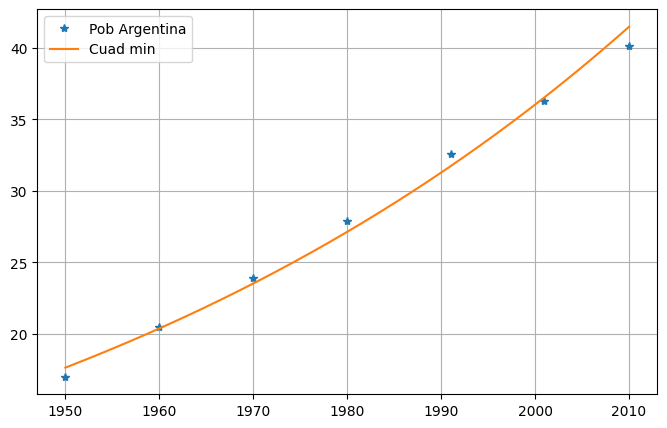

In [ ]:
# tabla valores original
tabla_x = np.array([1950, 1960, 1970, 1980, 1991, 2001, 2010])
tabla_y = np.array([17, 20.5, 23.9, 27.9, 32.6, 36.3, 40.1])

# tabla valores transformada para resolver por regresión lineal (ecuaciones normales)
tabla_t = np.log(tabla_x)
tabla_z = np.log(tabla_y)

# ecuaciones normales
fila_de_unos = np.ones(len(tabla_t))
At = np.array([fila_de_unos, tabla_t])
A = np.transpose(At)

coefs = np.linalg.solve(np.dot(At,A), np.dot(At,tabla_z)) #en el orden en que lo definí en el sistema
# print("Coeficientes por ecuaciones normales:", coefs)

### también puedo calcular cuad min con numpy.polynomial
# por supuesto uso la tabla de datos transformados
# grado = 1
# cuad_min_por_polynomial = Poly.fit(tabla_t, tabla_z, grado)
###

# grafico tabla
plt.plot(tabla_x, tabla_y, '*', label='Pob Argentina')

# grafico cuad min
def cuad_min(x,a,b):
  y = a*x**b
  return y
a_monio = coefs[0]
b = coefs[1]
a = np.exp(a_monio)
vals_x_graficar = np.linspace(1950,2010, 5000)
plt.plot(vals_x_graficar, cuad_min(vals_x_graficar,a,b), label='Cuad min')
plt.legend()
plt.grid()

# Error cuadrático medio
vals_y_cuad_min = cuad_min(tabla_x,a,b)
cant_datos = len(tabla_x)

ECM = (1/cant_datos)*np.linalg.norm(vals_y_cuad_min - tabla_y, ord=2)**2
print("Error cuadrático medio:", ECM)

# tabla_y_promedio = np.mean(vals_y)
# R2 = 1 - np.linalg.norm(vals_y_cuad_min - tabla_y, ord=2)**2 / np.linalg.norm(tabla_y - tabla_y_promedio, ord=2)**2
# print("Coeficiente de determinación R2:", R2)

## Ejemplo 5 (regresión no lineal, combinación de funciones): los siguientes datos corresponden a la población argentina expresada en millones de habitantes

\begin{align}
\begin{matrix}
\textbf{Año} & 1950 & 1960 & 1970 & 1980 & 1991 & 2001 & 2010\\ \hline
\textbf{Habitantes} & 17 & 20.5 & 23.9 & 27.9 & 32.6 & 36.3 & 40.1
\end{matrix}
\end{align}

1. ### Hallar la función $f(x)= a+bx+c\text{e}^{0.1x}$ que mejor aproxime a la tabla de datos en el sentido de cuadrados mínimos, resolviendo las ecuaciones normales.
  - ### ¿Podemos resolver por ecuaciones normales si la $f$ no es lineal?
  - ### ¿Y entonces qué hacemos? Escribir en papel esto.
2. ### Hacer un gráfico con los datos y la función encontrada.
1. ### Calcular error cuadrático medio. Interpretar y comparar con anteriores.
1. ### Estimar la población en el año 2006.

Error cuadrático medio: 0.04822318020667404
Población estimada en 2006 (en millones): 38.36163689548232


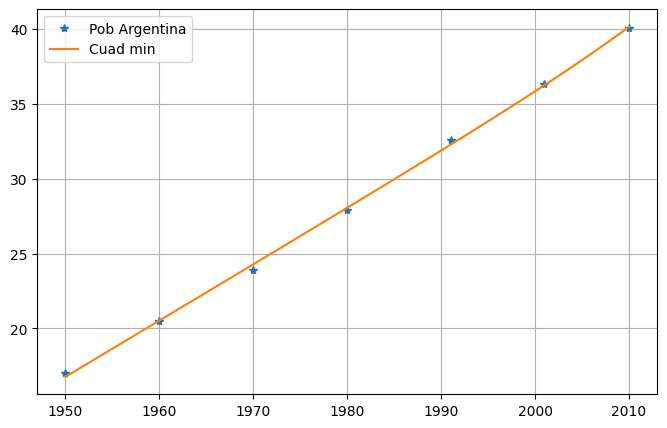

In [ ]:
# tabla valores original
tabla_x = np.array([1950, 1960, 1970, 1980, 1991, 2001, 2010])
tabla_y = np.array([17, 20.5, 23.9, 27.9, 32.6, 36.3, 40.1])


# ecuaciones normales
fila_de_unos = np.ones(len(tabla_x))
A_traspuesta = np.array([fila_de_unos, tabla_x, np.exp(0.1*tabla_x)])
A = np.transpose(A_traspuesta)

coefs = np.linalg.solve(np.dot(A_traspuesta,A), np.dot(A_traspuesta,tabla_y)) #en el orden en que lo definí en el sistema
# print("Coeficientes por ecuaciones normales:", coefs)

### Acá NO puedo usar numpy.polynomial

# grafico tabla
plt.plot(tabla_x, tabla_y, '*', label='Pob Argentina')

# grafico cuad min
def cuad_min(x,a,b,c):
  y = a + b*x + c*np.exp(0.1*x)
  return y
a = coefs[0]
b = coefs[1]
c = coefs[2]
vals_x_graficar = np.linspace(1950,2010, 5000)
plt.plot(vals_x_graficar, cuad_min(vals_x_graficar,a,b,c), label='Cuad min')
plt.legend()
plt.grid()

# Error cuadrático medio
vals_y_cuad_min = cuad_min(tabla_x,a,b,c)
cant_datos = len(tabla_x)

ECM = (1/cant_datos)*np.linalg.norm(vals_y_cuad_min - tabla_y, ord=2)**2
print("Error cuadrático medio:", ECM)

# tabla_y_promedio = np.mean(tabla_y)
# R2 = 1 - np.linalg.norm(vals_y_cuad_min - tabla_y, ord=2)**2 / np.linalg.norm(tabla_y - tabla_y_promedio, ord=2)**2
# print("Coeficiente de determinación R2:", R2)


# Población estimada en 2006
print("Población estimada en 2006 (en millones):", cuad_min(2006,a,b,c))